data load and import
dataframe ko shape
findout missing value
droping missing value
type of features
convert data time features
New additional column journey_day and journey_month
drop date of journey
extract hour, minute column and drop column dep_time and arriaval timr


In [69]:
#import pandas
import pandas as pd

In [70]:
df = pd.read_excel('Data_Train.xlsx')
df

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302
...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648


**We have to predict the price of airtickets**

Data Profiling and Inspection

In [71]:
#Checking the data types
df.dtypes

Airline            object
Date_of_Journey    object
Source             object
Destination        object
Route              object
Dep_Time           object
Arrival_Time       object
Duration           object
Total_Stops        object
Additional_Info    object
Price               int64
dtype: object

**Descritive static**

In [72]:
df.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


In [73]:
df.describe(include='int') #for numeric data

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


In [74]:
df.describe(include='object') #for categorical data

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info
count,10683,10683,10683,10683,10682,10683,10683,10683,10682,10683
unique,12,44,5,6,128,222,1343,368,5,10
top,Jet Airways,18/05/2019,Delhi,Cochin,DEL → BOM → COK,18:55,19:00,2h 50m,1 stop,No info
freq,3849,504,4537,4537,2376,233,423,550,5625,8345


In [75]:
df.shape #check the shape of data

(10683, 11)

**Overview overall information**

In [76]:
df.info() #viewing overall information of data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


**Checking null value**

In [77]:
df.isna().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

**Removing null rows**

In [78]:
df.isna().any(axis='columns').sum()

1

In [79]:
df.loc[df.isna().any(axis='columns')] # viewing null values row

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
9039,Air India,6/05/2019,Delhi,Cochin,NaN,09:45,09:25 07 May,23h 40m,NaN,No info,7480


In [80]:
df.dropna(inplace = True) #removing the null rows

In [81]:
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


**Converting Date_of_journy according to datetime**

In [82]:
date_of_journey = df['Date_of_Journey']
date_time = pd.to_datetime(date_of_journey)
df['Date_of_Journey'] = date_time

C:\Users\arun\AppData\Local\Temp\ipykernel_19428\1558927691.py:2: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  date_time = pd.to_datetime(date_of_journey)


**Extracting month and day and updating in original data**

In [83]:
df['month'] = pd.DatetimeIndex(df['Date_of_Journey']).month
df['day'] = pd.DatetimeIndex(df['Date_of_Journey']).day

In [84]:
df

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,month,day
0,IndiGo,2019-03-24,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,3,24
1,Air India,2019-05-01,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,5,1
2,Jet Airways,2019-06-09,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,6,9
3,IndiGo,2019-05-12,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,5,12
4,IndiGo,2019-03-01,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,2019-04-09,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107,4,9
10679,Air India,2019-04-27,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145,4,27
10680,Jet Airways,2019-04-27,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229,4,27
10681,Vistara,2019-03-01,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648,3,1


In [85]:
df['month'].dtypes # checking the data types of month

dtype('int32')

**Creating Date_of_journey DataFrame**

In [86]:
Date_of_Journey = df.loc[:,['Date_of_Journey']]
Date_of_Journey['month'] = pd.DatetimeIndex(df['Date_of_Journey']).month
Date_of_Journey['day'] = pd.DatetimeIndex(df['Date_of_Journey']).day

In [87]:
df

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,month,day
0,IndiGo,2019-03-24,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,3,24
1,Air India,2019-05-01,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,5,1
2,Jet Airways,2019-06-09,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,6,9
3,IndiGo,2019-05-12,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,5,12
4,IndiGo,2019-03-01,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,2019-04-09,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107,4,9
10679,Air India,2019-04-27,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145,4,27
10680,Jet Airways,2019-04-27,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229,4,27
10681,Vistara,2019-03-01,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648,3,1


**Dropping Data_of_journey from original dataframe**

In [88]:
df.drop(columns="Date_of_Journey", inplace=True)
df

,Airline,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,month,day
0,IndiGo,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,3,24
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,5,1
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,6,9
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,5,12
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107,4,9
10679,Air India,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145,4,27
10680,Jet Airways,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229,4,27
10681,Vistara,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648,3,1


**Extracting the Dep_Time**

In [89]:
dep_hours = pd.DatetimeIndex(df['Dep_Time']).hour
dep_minutes = pd.DatetimeIndex(df['Dep_Time']).minute

**Adding depature hours and minutes columns in original data**

In [90]:
df['Departure_hour'] = dep_hours
df['Departure_minute'] = dep_minutes

In [91]:
df

,Airline,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,month,day,Departure_hour,Departure_minute
0,IndiGo,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,3,24,22,20
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,5,1,5,50
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,6,9,9,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,5,12,18,5
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,3,1,16,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107,4,9,19,55
10679,Air India,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145,4,27,20,45
10680,Jet Airways,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229,4,27,8,20
10681,Vistara,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648,3,1,11,30


**Creating Dep_Time DataFrame**

In [92]:
Dep_time = df.loc[:,['Dep_Time']]
Dep_Time['Dep_hour'] = pd.DatetimeIndex(df['Dep_Time']).hour
Dep_Time['Dep_minute'] = pd.DatetimeIndex(df['Dep_Time']).minute
Dep_Time

,Dep_Time,Dep_hour,Dep_minute
0,22:20,22,20
1,05:50,5,50
2,09:25,9,25
3,18:05,18,5
4,16:50,16,50
...,...,...,...
10678,19:55,19,55
10679,20:45,20,45
10680,08:20,8,20
10681,11:30,11,30


**Droping Dep_Time column from original data**

In [93]:
df.drop(columns='Dep_Time', inplace=True)
df

,Airline,Source,Destination,Route,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,month,day,Departure_hour,Departure_minute
0,IndiGo,Banglore,New Delhi,BLR → DEL,01:10 22 Mar,2h 50m,non-stop,No info,3897,3,24,22,20
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,13:15,7h 25m,2 stops,No info,7662,5,1,5,50
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,04:25 10 Jun,19h,2 stops,No info,13882,6,9,9,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,23:30,5h 25m,1 stop,No info,6218,5,12,18,5
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,21:35,4h 45m,1 stop,No info,13302,3,1,16,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,Kolkata,Banglore,CCU → BLR,22:25,2h 30m,non-stop,No info,4107,4,9,19,55
10679,Air India,Kolkata,Banglore,CCU → BLR,23:20,2h 35m,non-stop,No info,4145,4,27,20,45
10680,Jet Airways,Banglore,Delhi,BLR → DEL,11:20,3h,non-stop,No info,7229,4,27,8,20
10681,Vistara,Banglore,New Delhi,BLR → DEL,14:10,2h 40m,non-stop,No info,12648,3,1,11,30


**Extracting arrival time**

In [94]:
arr_hour =  pd.DatetimeIndex(df['Arrival_Time']).hour # Extracting hour from Dep_Time
arr_minute =  pd.DatetimeIndex(df['Arrival_Time']).minute # Extracting minute from Dep_Time

**Adding arrival hours and minutes columns in original data**

In [95]:
df["Arrival_hour"] = arr_hour # adding new column "Arrival_hour" with arr_hour value
df["Arrival_minute"] = arr_minute # adding new column "Arrival_minute" with arr_minute value

In [96]:
df

,Airline,Source,Destination,Route,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,month,day,Departure_hour,Departure_minute,Arrival_hour,Arrival_minute
0,IndiGo,Banglore,New Delhi,BLR → DEL,01:10 22 Mar,2h 50m,non-stop,No info,3897,3,24,22,20,1,10
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,13:15,7h 25m,2 stops,No info,7662,5,1,5,50,13,15
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,04:25 10 Jun,19h,2 stops,No info,13882,6,9,9,25,4,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,23:30,5h 25m,1 stop,No info,6218,5,12,18,5,23,30
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,21:35,4h 45m,1 stop,No info,13302,3,1,16,50,21,35
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,Kolkata,Banglore,CCU → BLR,22:25,2h 30m,non-stop,No info,4107,4,9,19,55,22,25
10679,Air India,Kolkata,Banglore,CCU → BLR,23:20,2h 35m,non-stop,No info,4145,4,27,20,45,23,20
10680,Jet Airways,Banglore,Delhi,BLR → DEL,11:20,3h,non-stop,No info,7229,4,27,8,20,11,20
10681,Vistara,Banglore,New Delhi,BLR → DEL,14:10,2h 40m,non-stop,No info,12648,3,1,11,30,14,10


**Creating Arrival_Time DataFrame**

In [97]:
Arrival_time = df.loc[:,["Arrival_Time"]]
Arrival_time["Arrival_hour"] = arr_hour
Arrival_time["Arrival_minute"] = arr_minute

In [98]:
Arrival_time

,Arrival_Time,Arrival_hour,Arrival_minute
0,01:10 22 Mar,1,10
1,13:15,13,15
2,04:25 10 Jun,4,25
3,23:30,23,30
4,21:35,21,35
...,...,...,...
10678,22:25,22,25
10679,23:20,23,20
10680,11:20,11,20
10681,14:10,14,10


**Droping Arrival_Time from original data**

In [99]:
df.drop(columns="Arrival_Time", inplace=True)
df

,Airline,Source,Destination,Route,Duration,Total_Stops,Additional_Info,Price,month,day,Departure_hour,Departure_minute,Arrival_hour,Arrival_minute
0,IndiGo,Banglore,New Delhi,BLR → DEL,2h 50m,non-stop,No info,3897,3,24,22,20,1,10
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,7h 25m,2 stops,No info,7662,5,1,5,50,13,15
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,19h,2 stops,No info,13882,6,9,9,25,4,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,5h 25m,1 stop,No info,6218,5,12,18,5,23,30
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,4h 45m,1 stop,No info,13302,3,1,16,50,21,35
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,Kolkata,Banglore,CCU → BLR,2h 30m,non-stop,No info,4107,4,9,19,55,22,25
10679,Air India,Kolkata,Banglore,CCU → BLR,2h 35m,non-stop,No info,4145,4,27,20,45,23,20
10680,Jet Airways,Banglore,Delhi,BLR → DEL,3h,non-stop,No info,7229,4,27,8,20,11,20
10681,Vistara,Banglore,New Delhi,BLR → DEL,2h 40m,non-stop,No info,12648,3,1,11,30,14,10


**Converting duration according to timedelta**

In [100]:
df["Duration"] = pd.to_timedelta(df['Duration']) # converting duration according to timedelta and updating values

In [101]:
df

,Airline,Source,Destination,Route,Duration,Total_Stops,Additional_Info,Price,month,day,Departure_hour,Departure_minute,Arrival_hour,Arrival_minute
0,IndiGo,Banglore,New Delhi,BLR → DEL,0 days 02:50:00,non-stop,No info,3897,3,24,22,20,1,10
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,0 days 07:25:00,2 stops,No info,7662,5,1,5,50,13,15
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,0 days 19:00:00,2 stops,No info,13882,6,9,9,25,4,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,0 days 05:25:00,1 stop,No info,6218,5,12,18,5,23,30
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,0 days 04:45:00,1 stop,No info,13302,3,1,16,50,21,35
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,Kolkata,Banglore,CCU → BLR,0 days 02:30:00,non-stop,No info,4107,4,9,19,55,22,25
10679,Air India,Kolkata,Banglore,CCU → BLR,0 days 02:35:00,non-stop,No info,4145,4,27,20,45,23,20
10680,Jet Airways,Banglore,Delhi,BLR → DEL,0 days 03:00:00,non-stop,No info,7229,4,27,8,20,11,20
10681,Vistara,Banglore,New Delhi,BLR → DEL,0 days 02:40:00,non-stop,No info,12648,3,1,11,30,14,10


**Extracting hour and minute from Duration**

In [ ]:
duration_hour = df["Duration"].dt.components.hours # extracting hour from duration
duration_minute = df["Duration"].dt.components.minutes # extracting minute from duration

**Adding new column in original data**

In [103]:
df["Duration_hour"] = duration_hour # adding new column "Duration_hour" with duration_hour value
df["Duration_minute"] = duration_minute # adding new column "Duration_minute" with duration_minute value

In [104]:
df

,Airline,Source,Destination,Route,Duration,Total_Stops,Additional_Info,Price,month,day,Departure_hour,Departure_minute,Arrival_hour,Arrival_minute,Duration_hour,Duration_minute
0,IndiGo,Banglore,New Delhi,BLR → DEL,0 days 02:50:00,non-stop,No info,3897,3,24,22,20,1,10,2,50
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,0 days 07:25:00,2 stops,No info,7662,5,1,5,50,13,15,7,25
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,0 days 19:00:00,2 stops,No info,13882,6,9,9,25,4,25,19,0
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,0 days 05:25:00,1 stop,No info,6218,5,12,18,5,23,30,5,25
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,0 days 04:45:00,1 stop,No info,13302,3,1,16,50,21,35,4,45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,Kolkata,Banglore,CCU → BLR,0 days 02:30:00,non-stop,No info,4107,4,9,19,55,22,25,2,30
10679,Air India,Kolkata,Banglore,CCU → BLR,0 days 02:35:00,non-stop,No info,4145,4,27,20,45,23,20,2,35
10680,Jet Airways,Banglore,Delhi,BLR → DEL,0 days 03:00:00,non-stop,No info,7229,4,27,8,20,11,20,3,0
10681,Vistara,Banglore,New Delhi,BLR → DEL,0 days 02:40:00,non-stop,No info,12648,3,1,11,30,14,10,2,40


**Creating Duration DataFrame**

In [105]:
Duration = df.loc[:,["Duration"]]
Duration["Duration_hour"] = duration_hour
Duration["Duration_minute"] = duration_minute
Duration

,Duration,Duration_hour,Duration_minute
0,0 days 02:50:00,2,50
1,0 days 07:25:00,7,25
2,0 days 19:00:00,19,0
3,0 days 05:25:00,5,25
4,0 days 04:45:00,4,45
...,...,...,...
10678,0 days 02:30:00,2,30
10679,0 days 02:35:00,2,35
10680,0 days 03:00:00,3,0
10681,0 days 02:40:00,2,40


**Droping "Duration" column from original data**

In [106]:
df.drop(columns="Duration", inplace=True)
df

,Airline,Source,Destination,Route,Total_Stops,Additional_Info,Price,month,day,Departure_hour,Departure_minute,Arrival_hour,Arrival_minute,Duration_hour,Duration_minute
0,IndiGo,Banglore,New Delhi,BLR → DEL,non-stop,No info,3897,3,24,22,20,1,10,2,50
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,2 stops,No info,7662,5,1,5,50,13,15,7,25
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,2 stops,No info,13882,6,9,9,25,4,25,19,0
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,1 stop,No info,6218,5,12,18,5,23,30,5,25
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,1 stop,No info,13302,3,1,16,50,21,35,4,45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,Kolkata,Banglore,CCU → BLR,non-stop,No info,4107,4,9,19,55,22,25,2,30
10679,Air India,Kolkata,Banglore,CCU → BLR,non-stop,No info,4145,4,27,20,45,23,20,2,35
10680,Jet Airways,Banglore,Delhi,BLR → DEL,non-stop,No info,7229,4,27,8,20,11,20,3,0
10681,Vistara,Banglore,New Delhi,BLR → DEL,non-stop,No info,12648,3,1,11,30,14,10,2,40


**Extracting Route from data**

In [107]:
route_df = df["Route"]
route_df

0                    BLR → DEL
1        CCU → IXR → BBI → BLR
2        DEL → LKO → BOM → COK
3              CCU → NAG → BLR
4              BLR → NAG → DEL
                 ...          
10678                CCU → BLR
10679                CCU → BLR
10680                BLR → DEL
10681                BLR → DEL
10682    DEL → GOI → BOM → COK
Name: Route, Length: 10682, dtype: object

**Sperating route**

In [108]:
route_data = [route.split(" → ") for route in route_df]

**Assinging different routes**

In [109]:
rout_index_len =[len(data) for data in route_data]

In [110]:
max_route = max(rout_index_len)

**Extracting route from original data**

In [111]:
route1  = []
route2 = []
route3 = []
route4 = []
route5 = []
route6 = []
for route in route_data:
    if len(route) == 2:
        route1.append(route[0]) 
        route2.append(route[1]) 
        route3.append(None) 
        route4.append(None) 
        route5.append(None) 
        route6.append(None) 
    elif len(route) == 3:
        route1.append(route[0]) 
        route2.append(route[1]) 
        route3.append(route[2]) 
        route4.append(None) 
        route5.append(None) 
        route6.append(None) 
    elif len(route) == 4:
        route1.append(route[0]) 
        route2.append(route[1]) 
        route3.append(route[2]) 
        route4.append(route[3]) 
        route5.append(None) 
        route6.append(None) 
    elif len(route) == 5:
        route1.append(route[0]) 
        route2.append(route[1]) 
        route3.append(route[2]) 
        route4.append(route[3]) 
        route5.append(route[4]) 
        route6.append(None) 

    elif len(route) == 6:
        route1.append(route[0]) 
        route2.append(route[1]) 
        route3.append(route[2]) 
        route4.append(route[3]) 
        route5.append(route[4]) 
        route6.append(route[5])

**Creating Route DataFrame**

In [112]:
route_dataframe = df.loc[:,["Route"]]
route_dataframe

,Route
0,BLR → DEL
1,CCU → IXR → BBI → BLR
2,DEL → LKO → BOM → COK
3,CCU → NAG → BLR
4,BLR → NAG → DEL
...,...
10678,CCU → BLR
10679,CCU → BLR
10680,BLR → DEL
10681,BLR → DEL


**Adding the new column in route_dataframe**

In [113]:
route_dataframe["Route1"] = route1
route_dataframe["Route2"] = route2
route_dataframe["Route3"] = route3
route_dataframe["Route4"] = route4
route_dataframe["Route5"] = route5
route_dataframe["Route6"] = route6

In [114]:
route_dataframe

,Route,Route1,Route2,Route3,Route4,Route5,Route6
0,BLR → DEL,BLR,DEL,None,None,None,None
1,CCU → IXR → BBI → BLR,CCU,IXR,BBI,BLR,None,None
2,DEL → LKO → BOM → COK,DEL,LKO,BOM,COK,None,None
3,CCU → NAG → BLR,CCU,NAG,BLR,None,None,None
4,BLR → NAG → DEL,BLR,NAG,DEL,None,None,None
...,...,...,...,...,...,...,...
10678,CCU → BLR,CCU,BLR,None,None,None,None
10679,CCU → BLR,CCU,BLR,None,None,None,None
10680,BLR → DEL,BLR,DEL,None,None,None,None
10681,BLR → DEL,BLR,DEL,None,None,None,None


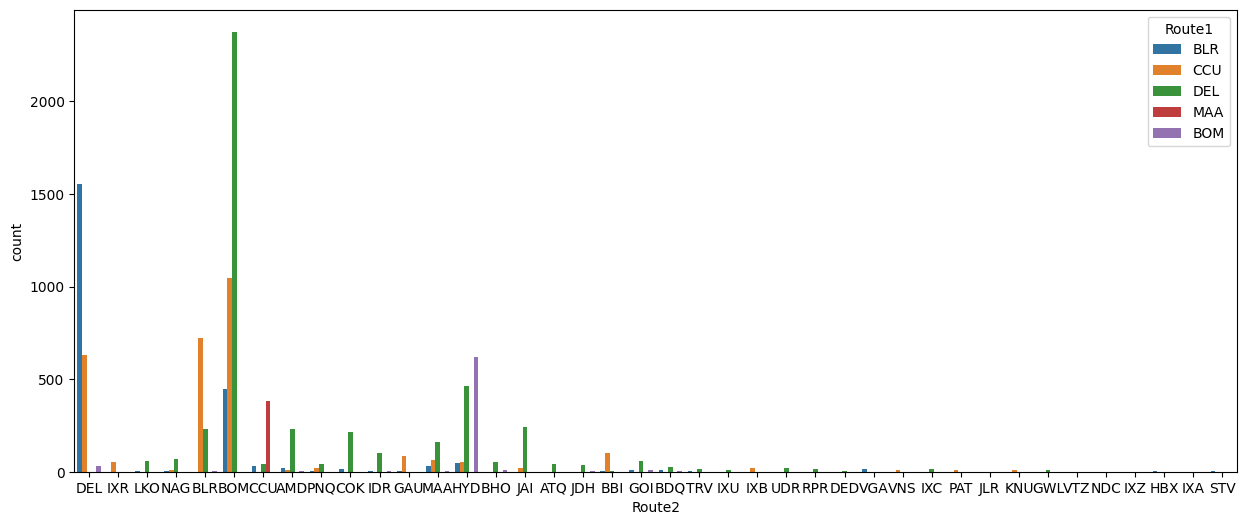

In [115]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(15,6))
sns.countplot(x="Route2", hue="Route1", data=route_dataframe)
plt.show()

In [116]:
route_dataframe.isna().sum()

Route         0
Route1        0
Route2        0
Route3     3491
Route4     9116
Route5    10636
Route6    10681
dtype: int64

**Adding new columns in original data**

In [117]:
df["Route1"] = route1
df["Route2"] = route2
df["Route3"] = route3
df["Route4"] = route4
df["Route5"] = route5
df["Route6"] = route6

In [118]:
df

,Airline,Source,Destination,Route,Total_Stops,Additional_Info,Price,month,day,Departure_hour,...,Arrival_hour,Arrival_minute,Duration_hour,Duration_minute,Route1,Route2,Route3,Route4,Route5,Route6
0,IndiGo,Banglore,New Delhi,BLR → DEL,non-stop,No info,3897,3,24,22,...,1,10,2,50,BLR,DEL,None,None,None,None
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,2 stops,No info,7662,5,1,5,...,13,15,7,25,CCU,IXR,BBI,BLR,None,None
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,2 stops,No info,13882,6,9,9,...,4,25,19,0,DEL,LKO,BOM,COK,None,None
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,1 stop,No info,6218,5,12,18,...,23,30,5,25,CCU,NAG,BLR,None,None,None
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,1 stop,No info,13302,3,1,16,...,21,35,4,45,BLR,NAG,DEL,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,Kolkata,Banglore,CCU → BLR,non-stop,No info,4107,4,9,19,...,22,25,2,30,CCU,BLR,None,None,None,None
10679,Air India,Kolkata,Banglore,CCU → BLR,non-stop,No info,4145,4,27,20,...,23,20,2,35,CCU,BLR,None,None,None,None
10680,Jet Airways,Banglore,Delhi,BLR → DEL,non-stop,No info,7229,4,27,8,...,11,20,3,0,BLR,DEL,None,None,None,None
10681,Vistara,Banglore,New Delhi,BLR → DEL,non-stop,No info,12648,3,1,11,...,14,10,2,40,BLR,DEL,None,None,None,None


**Route vs Total stops**

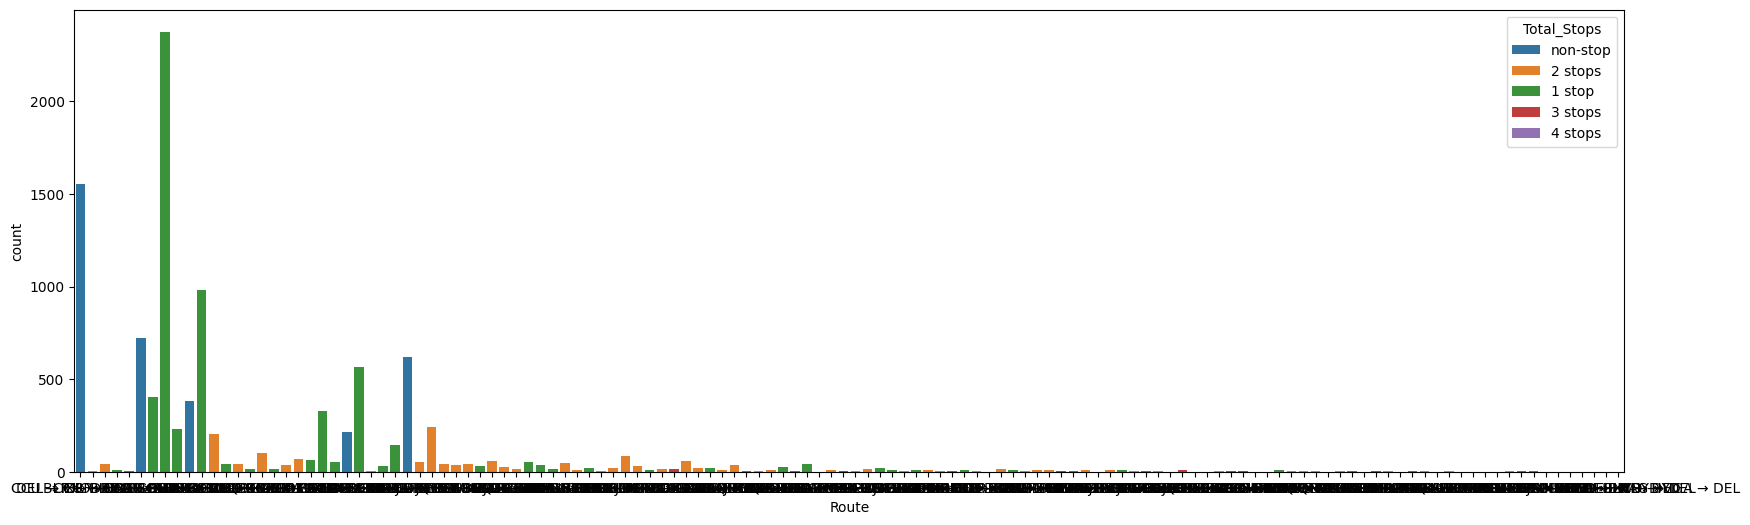

In [119]:
plt.figure(figsize=(20,6))
sns.countplot(x="Route",hue="Total_Stops", data=df)
plt.show()

**Droping Route column from original data**

In [120]:
df.drop(columns="Route", inplace=True)
df

,Airline,Source,Destination,Total_Stops,Additional_Info,Price,month,day,Departure_hour,Departure_minute,Arrival_hour,Arrival_minute,Duration_hour,Duration_minute,Route1,Route2,Route3,Route4,Route5,Route6
0,IndiGo,Banglore,New Delhi,non-stop,No info,3897,3,24,22,20,1,10,2,50,BLR,DEL,None,None,None,None
1,Air India,Kolkata,Banglore,2 stops,No info,7662,5,1,5,50,13,15,7,25,CCU,IXR,BBI,BLR,None,None
2,Jet Airways,Delhi,Cochin,2 stops,No info,13882,6,9,9,25,4,25,19,0,DEL,LKO,BOM,COK,None,None
3,IndiGo,Kolkata,Banglore,1 stop,No info,6218,5,12,18,5,23,30,5,25,CCU,NAG,BLR,None,None,None
4,IndiGo,Banglore,New Delhi,1 stop,No info,13302,3,1,16,50,21,35,4,45,BLR,NAG,DEL,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,Kolkata,Banglore,non-stop,No info,4107,4,9,19,55,22,25,2,30,CCU,BLR,None,None,None,None
10679,Air India,Kolkata,Banglore,non-stop,No info,4145,4,27,20,45,23,20,2,35,CCU,BLR,None,None,None,None
10680,Jet Airways,Banglore,Delhi,non-stop,No info,7229,4,27,8,20,11,20,3,0,BLR,DEL,None,None,None,None
10681,Vistara,Banglore,New Delhi,non-stop,No info,12648,3,1,11,30,14,10,2,40,BLR,DEL,None,None,None,None


**Manipulating Total stops columns in the dataframe**

In [121]:
stop_data = df["Total_Stops"]

In [122]:
new_df = df.loc[:,["Total_Stops"]]
new_df

,Total_Stops
0,non-stop
1,2 stops
2,2 stops
3,1 stop
4,1 stop
...,...
10678,non-stop
10679,non-stop
10680,non-stop
10681,non-stop


In [123]:
list = []
for item in stop_data:
    if item == 'non-stop':
        list.append(0)
    elif item == '1 stop':
        list.append(1)
    elif item == '2 stops':
        list.append(2)
    elif item == '3 stops':
        list.append(3)
    elif item == '4 stops':
        list.append(4)

In [124]:
new_df["Total_Stops"]=list #adding new value in total_stops

In [125]:
new_df

,Total_Stops
0,0
1,2
2,2
3,1
4,1
...,...
10678,0
10679,0
10680,0
10681,0


In [126]:
stop_value = {'non-stop':0,'1 stop':1,'2 stops':2,'3 stops':3,'4 stops':4}

In [127]:
df["Total_Stops"].map(stop_value)

0        0
1        2
2        2
3        1
4        1
        ..
10678    0
10679    0
10680    0
10681    0
10682    2
Name: Total_Stops, Length: 10682, dtype: int64

In [128]:
df["Total_Stops"].replace(["non-stop","1 stop","2 stops","3 stops","4 stops"],[0,1,2,3,4], inplace=True)

In [143]:
df

,Airline,Source,Destination,Total_Stops,Additional_Info,Price,month,day,Departure_hour,Departure_minute,Arrival_hour,Arrival_minute,Duration_hour,Duration_minute,Route1,Route2,Route3,Route4,Route5,Route6
0,IndiGo,Banglore,New Delhi,0,No info,3897,3,24,22,20,1,10,2,50,BLR,DEL,None,None,None,None
1,Air India,Kolkata,Banglore,2,No info,7662,5,1,5,50,13,15,7,25,CCU,IXR,BBI,BLR,None,None
2,Jet Airways,Delhi,Cochin,2,No info,13882,6,9,9,25,4,25,19,0,DEL,LKO,BOM,COK,None,None
3,IndiGo,Kolkata,Banglore,1,No info,6218,5,12,18,5,23,30,5,25,CCU,NAG,BLR,None,None,None
4,IndiGo,Banglore,New Delhi,1,No info,13302,3,1,16,50,21,35,4,45,BLR,NAG,DEL,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,Kolkata,Banglore,0,No info,4107,4,9,19,55,22,25,2,30,CCU,BLR,None,None,None,None
10679,Air India,Kolkata,Banglore,0,No info,4145,4,27,20,45,23,20,2,35,CCU,BLR,None,None,None,None
10680,Jet Airways,Banglore,Delhi,0,No info,7229,4,27,8,20,11,20,3,0,BLR,DEL,None,None,None,None
10681,Vistara,Banglore,New Delhi,0,No info,12648,3,1,11,30,14,10,2,40,BLR,DEL,None,None,None,None


**Maniputing additional_info columns from original data**

In [144]:
df["Additional_Info"]

0        No info
1        No info
2        No info
3        No info
4        No info
          ...   
10678    No info
10679    No info
10680    No info
10681    No info
10682    No info
Name: Additional_Info, Length: 10682, dtype: object

In [145]:
df["Additional_Info"].unique()

array(['No info', 'In-flight meal not included',
       'No check-in baggage included', '1 Short layover', 'No Info',
       '1 Long layover', 'Change airports', 'Business class',
       'Red-eye flight', '2 Long layover'], dtype=object)

<AxesSubplot:xlabel='Price'>

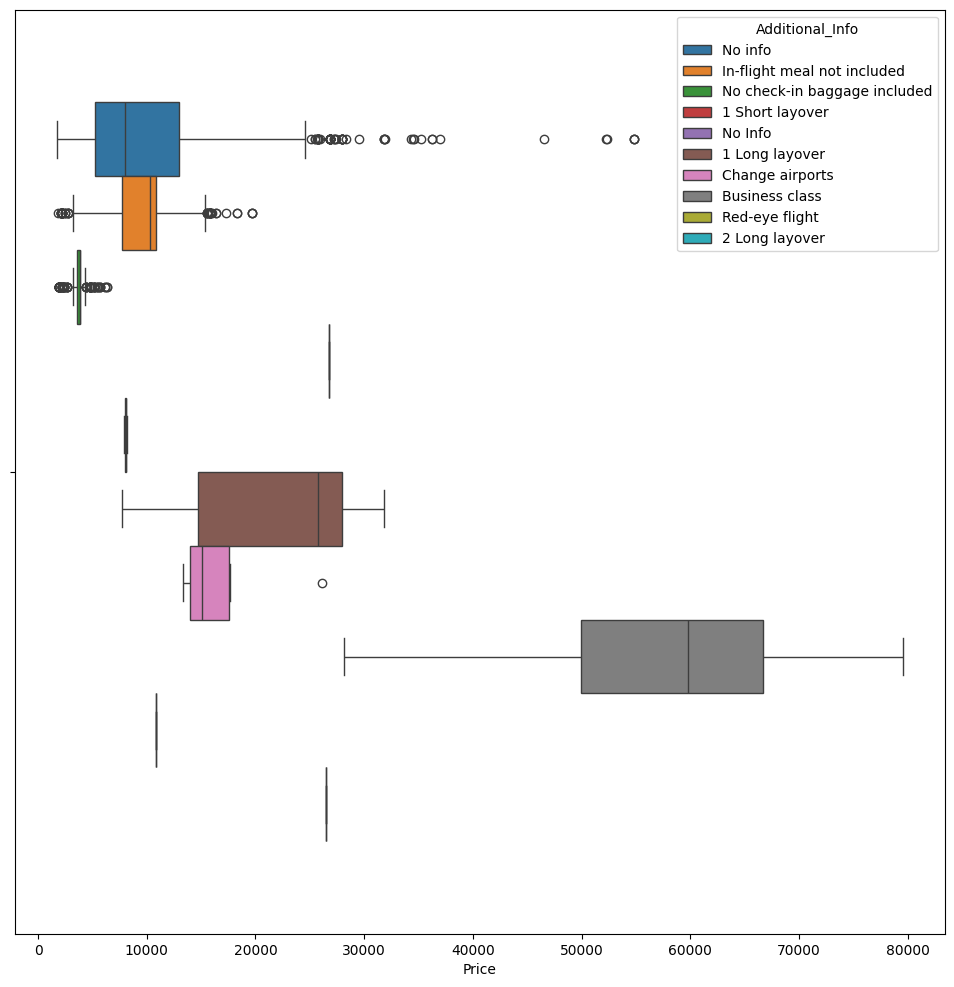

In [146]:
plt.figure(figsize=(12,12))
sns.boxplot(x="Price", hue="Additional_Info", data=df)

**Manipulating airline column from original data**

In [147]:
df["Airline"].unique()

array(['IndiGo', 'Air India', 'Jet Airways', 'SpiceJet',
       'Multiple carriers', 'GoAir', 'Vistara', 'Air Asia',
       'Vistara Premium economy', 'Jet Airways Business',
       'Multiple carriers Premium economy', 'Trujet'], dtype=object)

In [148]:
df["Airline"].nunique()

12

<AxesSubplot:xlabel='Price'>

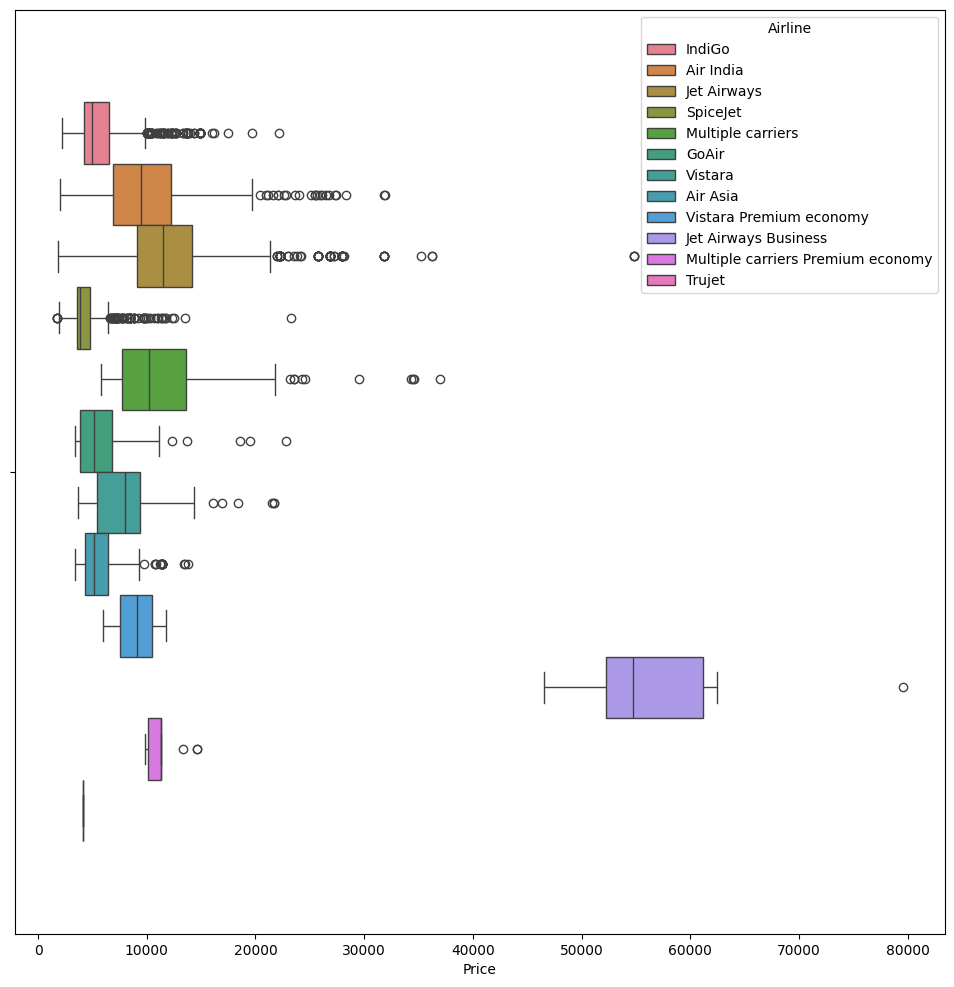

In [149]:
plt.figure(figsize=(12,12))
sns.boxplot(x="Price", hue="Airline", data=df)

In [150]:
airline_data = df["Airline"].value_counts()
airline_data

Airline
Jet Airways                          3849
IndiGo                               2053
Air India                            1751
Multiple carriers                    1196
SpiceJet                              818
Vistara                               479
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64

**Exploratory Data Analysis**

Disturibution of Airline

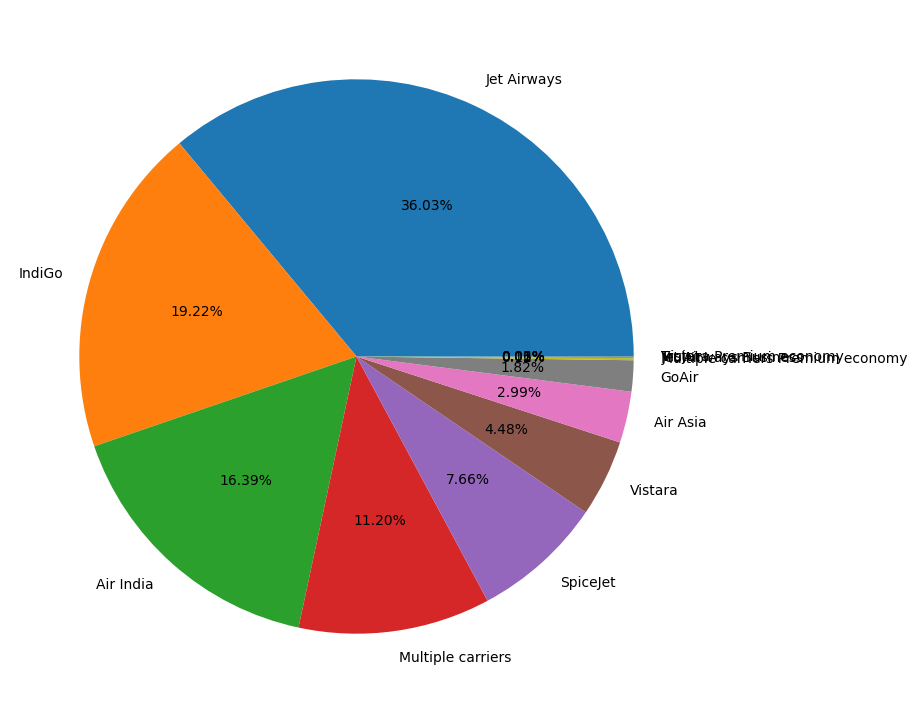

In [151]:
#piechart
plt.figure(figsize=(9,9))
plt.pie(x=airline_data.values, labels=airline_data.index , autopct="%.2f%%")
plt.show()

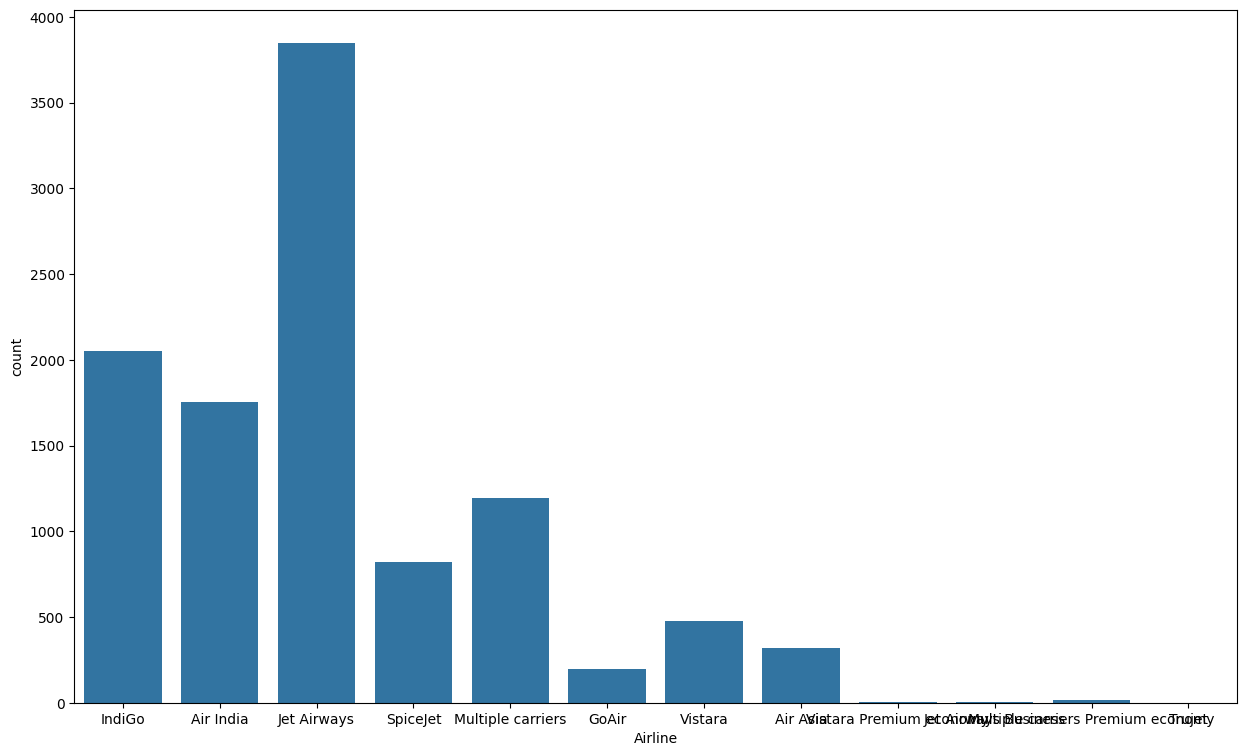

In [152]:
#using bar chart
plt.figure(figsize=(15,9))
sns.countplot(x="Airline", data=df)
plt.show()

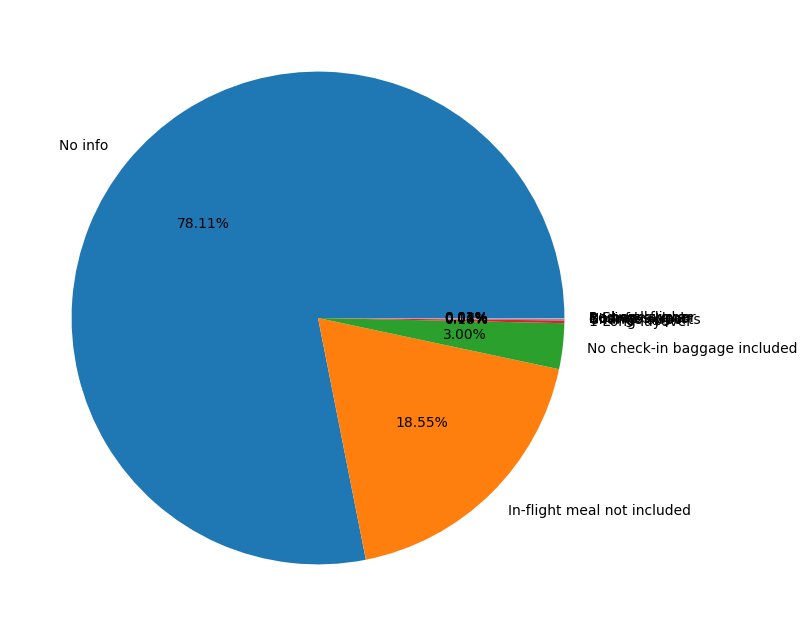

In [153]:
#Disturibution of Additional_Info
a_i = df["Additional_Info"].value_counts()
plt.figure(figsize=(8,8))
plt.pie(a_i.values, labels=a_i.index, autopct="%.2f%%")
plt.show()

**Destribution of Total_stops**

<AxesSubplot:xlabel='Total_Stops', ylabel='count'>

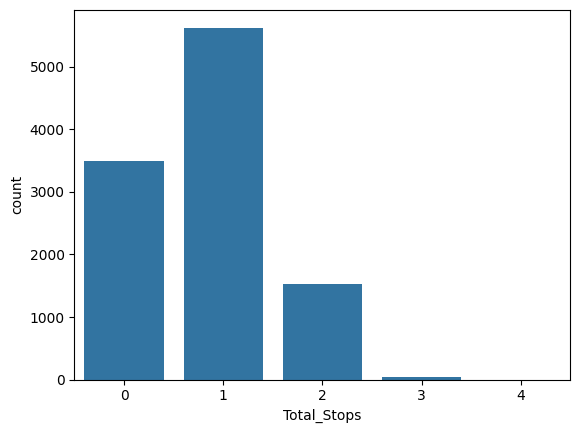

In [154]:
sns.countplot(x=df["Total_Stops"])

**Destribution of Duration_hour and Duration_minute**

<AxesSubplot:xlabel='Duration_hour', ylabel='count'>

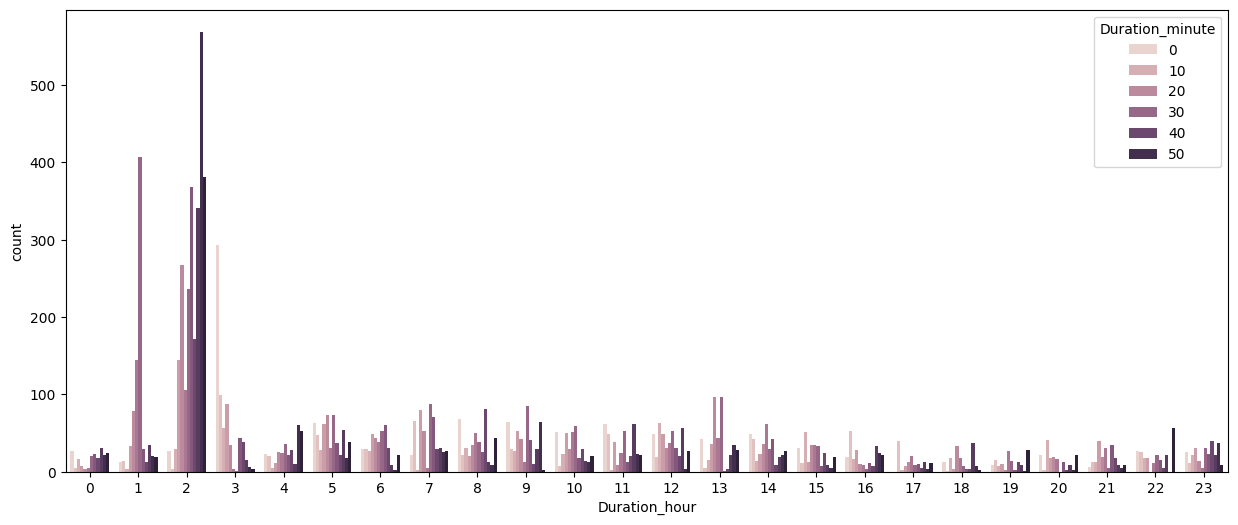

In [155]:
plt.figure(figsize=(15,6))
sns.countplot(x=df["Duration_hour"], hue=df["Duration_minute"])

**Destribution of Depature_hour and Depature_minute**

<AxesSubplot:xlabel='Departure_hour', ylabel='count'>

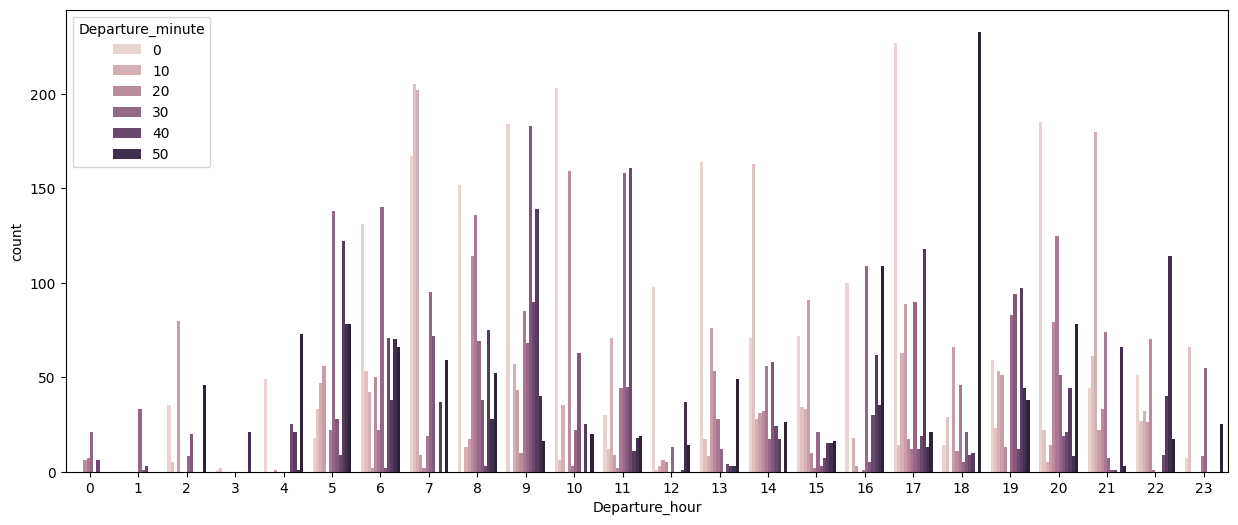

In [158]:
plt.figure(figsize=(15,6))
sns.countplot(x=df["Departure_hour"], hue=df["Departure_minute"])

**Destribution of Arrival_hour and Arrival_minute**

<AxesSubplot:xlabel='Arrival_hour', ylabel='count'>

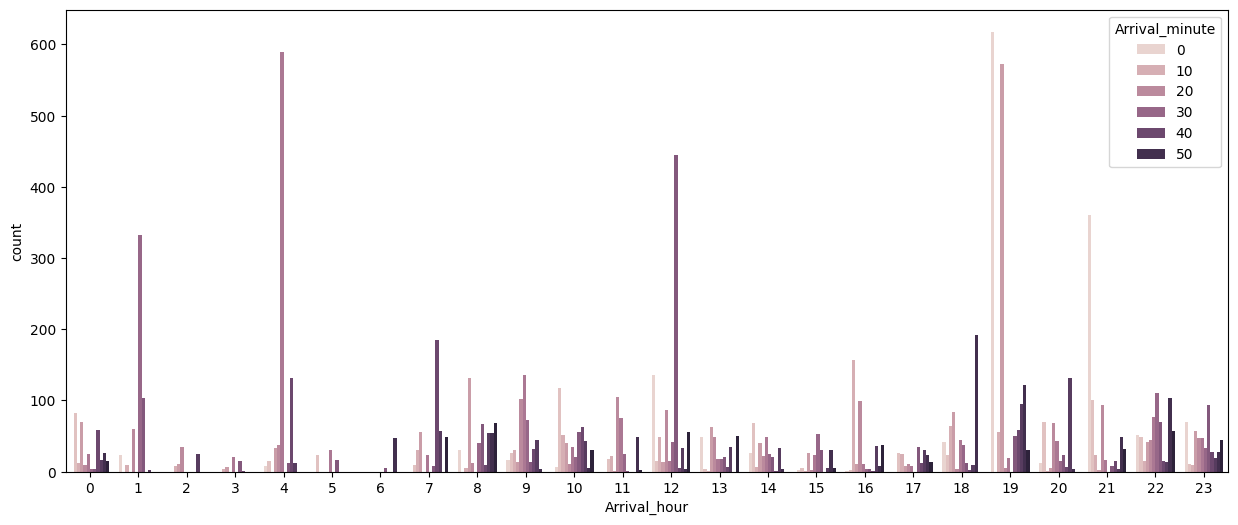

In [159]:
plt.figure(figsize=(15,6))
sns.countplot(x=df["Arrival_hour"], hue=df["Arrival_minute"])

**We need to predict Price of flight**

In [161]:
X = df.loc[:,["Airline", "Total_Stops", "Additional_Info", "month", "day", "Departure_hour", "Departure_minute", "Arrival_hour", "Arrival_minute", "Duration_hour", "Duration_minute"]]
y = df.Price

In [163]:
X

,Airline,Total_Stops,Additional_Info,month,day,Departure_hour,Departure_minute,Arrival_hour,Arrival_minute,Duration_hour,Duration_minute
0,IndiGo,0,No info,3,24,22,20,1,10,2,50
1,Air India,2,No info,5,1,5,50,13,15,7,25
2,Jet Airways,2,No info,6,9,9,25,4,25,19,0
3,IndiGo,1,No info,5,12,18,5,23,30,5,25
4,IndiGo,1,No info,3,1,16,50,21,35,4,45
...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,0,No info,4,9,19,55,22,25,2,30
10679,Air India,0,No info,4,27,20,45,23,20,2,35
10680,Jet Airways,0,No info,4,27,8,20,11,20,3,0
10681,Vistara,0,No info,3,1,11,30,14,10,2,40


In [164]:
X_features = pd.get_dummies(data=X , columns=['Airline','Additional_Info'],drop_first=True,dtype=float)
X_features

,Total_Stops,month,day,Departure_hour,Departure_minute,Arrival_hour,Arrival_minute,Duration_hour,Duration_minute,Airline_Air India,...,Airline_Vistara Premium economy,Additional_Info_1 Short layover,Additional_Info_2 Long layover,Additional_Info_Business class,Additional_Info_Change airports,Additional_Info_In-flight meal not included,Additional_Info_No Info,Additional_Info_No check-in baggage included,Additional_Info_No info,Additional_Info_Red-eye flight
0,0,3,24,22,20,1,10,2,50,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,2,5,1,5,50,13,15,7,25,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,2,6,9,9,25,4,25,19,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1,5,12,18,5,23,30,5,25,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,1,3,1,16,50,21,35,4,45,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,0,4,9,19,55,22,25,2,30,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
10679,0,4,27,20,45,23,20,2,35,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
10680,0,4,27,8,20,11,20,3,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
10681,0,3,1,11,30,14,10,2,40,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [165]:
X_features.columns

Index(['Total_Stops', 'month', 'day', 'Departure_hour', 'Departure_minute',
       'Arrival_hour', 'Arrival_minute', 'Duration_hour', 'Duration_minute',
       'Airline_Air India', 'Airline_GoAir', 'Airline_IndiGo',
       'Airline_Jet Airways', 'Airline_Jet Airways Business',
       'Airline_Multiple carriers',
       'Airline_Multiple carriers Premium economy', 'Airline_SpiceJet',
       'Airline_Trujet', 'Airline_Vistara', 'Airline_Vistara Premium economy',
       'Additional_Info_1 Short layover', 'Additional_Info_2 Long layover',
       'Additional_Info_Business class', 'Additional_Info_Change airports',
       'Additional_Info_In-flight meal not included',
       'Additional_Info_No Info',
       'Additional_Info_No check-in baggage included',
       'Additional_Info_No info', 'Additional_Info_Red-eye flight'],
      dtype='object')

**Train test split**

In [166]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_features, y, test_size=0.2, random_state=40)

In [167]:
X_train.shape, y_train.shape

((8545, 29), (8545,))

In [168]:
X_test.shape, y_test.shape

((2137, 29), (2137,))

**Modeling: Multiple Linear Regression**

In [169]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train,y_train)

LinearRegression()

In [170]:
#Prediction
y_pred = model.predict(X_test)

In [171]:
#coefficient
m = model.coef_
print(f"The cofficient of data are {m}.")

The cofficient of data are [ 2.87705361e+03 -5.57224398e+02 -6.92820048e+01  2.02755788e+01
 -2.54433314e+00 -6.32292795e+00 -1.83723729e+00  3.68384079e+01
  5.06374626e-01  1.38947138e+03  1.66928235e+02  1.83598839e+02
  5.93583445e+03  3.89199498e+04  3.93388641e+03  4.23794436e+03
 -2.96967961e+02 -4.48916949e+03  2.10063124e+03  3.35557123e+03
 -5.45696821e-12  4.49092228e+03  1.16277561e+04 -5.20158718e+03
 -1.25198879e+04 -1.00668962e+04 -9.24290159e+03 -8.97978032e+03
  0.00000000e+00].


In [172]:
#Interception
c = model.intercept_
print(f"The interception of data is {c}.")

The interception of data is 16588.20132029691.


**Evaluation**

In [173]:
# calculating mse
def mean_square_error(y_true, y_pred):
    error = y_true - y_pred
    error_sq = [item**2 for item in error]
    mse = (1/len(y_true))* sum(error_sq)
    return mse

In [174]:
mse = mean_square_error(y_true=y_test, y_pred=y_pred)
print(f"Mean Square error is {round(mse,4)}.")

Mean Square error is 7525820.7332.


In [175]:
# using sklearn libraries
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_true=y_test, y_pred=y_pred)
mse

7525820.73320457

**Evalution**

In [176]:
# calculating Mean Square Error_root(mser)
def mean_square_error_root(y_true, y_pred):
    error = y_true - y_pred
    error_sq = [item**2 for item in error]
    mser = ((1/len(y_true))* sum(error_sq)) ** (1/2)
    return mser

In [177]:
mser = mean_square_error_root(y_true=y_test, y_pred=y_pred)
print(f"Root Mean Square Error is {round(mser,4)}.")

Root Mean Square Error is 2743.3229.


In [179]:
pip install sklearn.metrics

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement sklearn.metrics (from versions: none)
ERROR: No matching distribution found for sklearn.metrics


In [189]:
# using sklearn libraries
from sklearn.metrics import mean_squared_error
mser = mean_squared_error(y_true=y_test, y_pred=y_pred)
print(np.sqrt(mser))

2743.3229363683326


In [190]:
# calculating Mean Absolute Error(mae)
def mean_absolute_error(y_true, y_pred):
    error = y_true - y_pred
    error_ab = [(item**2)**(1/2) for item in error]
    mae = ((1/len(y_true))* sum(error_ab))
    return mae

In [191]:
mae = mean_absolute_error(y_true=y_test, y_pred=y_pred)
print(f"Mean Absolute Error is {round(mae,4)}.")

Mean Absolute Error is 1878.8883.


In [195]:
# using sklearn libraries
from sklearn.metrics import mean_absolute_error
maee = mean_absolute_error(y_true=y_test, y_pred=y_pred)
maee

1878.888282609098

In [192]:
# calculating R square
def r2_score(y_true, y_pred):
    e_r = y_test - y_pred
    e_t = y_test - y_test.mean()
    ssr = [item ** 2 for item in e_r]
    sst = [item ** 2 for item in e_t]
    r2 = 1-(sum(ssr)/ sum(sst))
    return r2

In [193]:
r2 = r2_score(y_true=y_test, y_pred=y_pred)
print(f"R Square score is {round(r2,4)}.")

R Square score is 0.663.


In [194]:
# using sklearn libraries
from sklearn.metrics import r2_score
r_s= r2_score(y_true=y_test, y_pred=y_pred)
r_s

0.6629782791408793